> **Superseded (2026-09-22).** Use `python -m src.experiments.run_ablation` (writes `reports/ablation_results/`). This notebook pools splits that were already scaled with the train-fitted scaler and uses the pre-fix ensemble/resampling API, so it no longer runs as-is. Kept for reference; its original outputs are in `archive/results_pre_fix_2026-09-22/`.

In [1]:
import sys
sys.path.insert(0, "..")

import warnings
warnings.filterwarnings("ignore")

import json
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split

logging.getLogger().setLevel(logging.WARNING)  # quiet the underlying modules' INFO logs for this run
sns.set_theme(style="whitegrid")

from src.data.ingest import load_config, load_dataset_config
from src.resampling.apply_resampling import apply_adaptive_resampling
from src.pipeline import apply_plain_smote
from src.ensemble.stacking import ConfidenceWeightedStackingEnsemble
from src.evaluation.metrics import compute_metrics, aggregate_metrics, metrics_to_dataframe
from src.evaluation.significance_test import compare_metrics_across_folds, summarize_comparison 

In [2]:
QUICK_TEST = False  # <-- flip to False for final report numbers

DATASETS = ["creditcard", "mammography"]
VARIANTS = ["ars_stack", "plain_smote", "unweighted_stacking"]

if QUICK_TEST:
    N_SPLITS = 3
    N_REPEATS = 1
    QUICK_N_ESTIMATORS = 50
    CREDITCARD_SUBSAMPLE = 15000  # rows; None = use full dataset
else:
    N_SPLITS = 5
    N_REPEATS = 3
    QUICK_N_ESTIMATORS = None  # use configs/models/ensemble.yaml as-is
    CREDITCARD_SUBSAMPLE = None

RANDOM_STATE = 42
RESULTS_DIR = Path("../reports/ablation_results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"QUICK_TEST={QUICK_TEST} | folds={N_SPLITS} x repeats={N_REPEATS} = {N_SPLITS*N_REPEATS} paired samples per comparison")


QUICK_TEST=False | folds=5 x repeats=3 = 15 paired samples per comparison


In [3]:
import time
start = time.time()
def load_pooled_dataset(dataset_name: str, configs_dir: str = "../configs"):
    ds_full_cfg = load_dataset_config(dataset_name, configs_dir)
    ds_cfg = ds_full_cfg["dataset"]
    target_column = ds_cfg["target_column"]
    positive_label = ds_cfg["positive_label"]

    processed_dir = Path(ds_cfg["processed_file"]).parent
    processed_dir = Path("..") / processed_dir if not str(processed_dir).startswith("..") else processed_dir

    parts = []
    for split in ["train", "val", "test"]:
        path = processed_dir / f"{dataset_name}_{split}.csv"
        if not path.exists():
            raise FileNotFoundError(f"{path} not found. Run src/data/preprocess.py for '{dataset_name}' first.")
        parts.append(pd.read_csv(path))
    full_df = pd.concat(parts, ignore_index=True)

    if dataset_name == "creditcard" and CREDITCARD_SUBSAMPLE is not None and len(full_df) > CREDITCARD_SUBSAMPLE:
        full_df = full_df.groupby(target_column, group_keys=False).apply(
            lambda g: g.sample(frac=CREDITCARD_SUBSAMPLE / len(full_df), random_state=RANDOM_STATE)
        ).reset_index(drop=True)
        print(f"  Subsampled creditcard to {len(full_df)} rows for QUICK_TEST")

    X = full_df.drop(columns=[target_column]).values
    y = full_df[target_column].values
    return X, y, positive_label, ds_cfg


for name in DATASETS:
    X, y, pos_label, _ = load_pooled_dataset(name)
    print(f"{name}: {X.shape[0]} rows, {X.shape[1]} features, class balance = {dict(zip(*np.unique(y, return_counts=True)))}")


creditcard: 284807 rows, 30 features, class balance = {np.int64(0): np.int64(284315), np.int64(1): np.int64(492)}
mammography: 11183 rows, 6 features, class balance = {np.int64(0): np.int64(10923), np.int64(1): np.int64(260)}


In [4]:
def load_model_configs(configs_dir: str = "../configs"):
    clustering_cfg = load_config(Path(configs_dir) / "models" / "clustering.yaml")["clustering"]
    resamplers_cfg = load_config(Path(configs_dir) / "models" / "resamplers.yaml")["resamplers"]
    ensemble_cfg = load_config(Path(configs_dir) / "models" / "ensemble.yaml")["ensemble"]

    if QUICK_TEST and QUICK_N_ESTIMATORS is not None:
        for learner_params in ensemble_cfg["base_learners"].values():
            if "n_estimators" in learner_params:
                learner_params["n_estimators"] = QUICK_N_ESTIMATORS

    return clustering_cfg, resamplers_cfg, ensemble_cfg


clustering_cfg, resamplers_cfg, ensemble_cfg = load_model_configs()
print("Base learner n_estimators:", {k: v.get("n_estimators") for k, v in ensemble_cfg["base_learners"].items()})


Base learner n_estimators: {'random_forest': 300, 'xgboost': 300, 'lightgbm': 300}


In [5]:
def run_variant_on_fold(X_train_outer, y_train_outer, X_test_outer, y_test_outer, positive_label, variant):
    # Inner split: carve a validation set out of this fold's training portion
    # (used for confidence weighting — never touches the outer test fold).
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train_outer, y_train_outer, test_size=0.15, stratify=y_train_outer, random_state=RANDOM_STATE,
    )

    variant_ensemble_cfg = dict(ensemble_cfg)
    if variant == "unweighted_stacking":
        variant_ensemble_cfg = {**ensemble_cfg, "confidence_weighting": {"enabled": False}}

    if variant == "plain_smote":
        X_tr_res, y_tr_res, _ = apply_plain_smote(X_tr, y_tr, resamplers_cfg, positive_label)
    else:  # "ars_stack" and "unweighted_stacking" both use adaptive resampling
        X_tr_res, y_tr_res, _ = apply_adaptive_resampling(
            X_tr, y_tr, positive_label, clustering_cfg, resamplers_cfg,
        )

    model = ConfidenceWeightedStackingEnsemble(variant_ensemble_cfg)
    model.fit(X_tr_res, y_tr_res, X_val, y_val)

    # y_pred = model.predict(X_test_outer)
    # y_proba = model.predict_proba(X_test_outer)[:, 1]
    # return compute_metrics(y_test_outer, y_pred, y_proba, task_type="binary")
    y_pred = model.predict(X_test_outer)
    y_proba = model.predict_proba(X_test_outer)[:, 1]
    metrics = compute_metrics(y_test_outer, y_pred, y_proba, task_type="binary")

    from sklearn.metrics import recall_score
    metrics["minority_recall"] = recall_score(y_test_outer, y_pred, pos_label=1)
    metrics["majority_recall"] = recall_score(y_test_outer, y_pred, pos_label=0)

    return metrics


In [6]:
def repeated_cv_experiment(dataset_name: str, variant: str):
    X, y, positive_label, _ = load_pooled_dataset(dataset_name)
    rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE)

    fold_metrics = []
    for fold_idx, (train_idx, test_idx) in enumerate(rskf.split(X, y)):
        X_train_outer, X_test_outer = X[train_idx], X[test_idx]
        y_train_outer, y_test_outer = y[train_idx], y[test_idx]

        metrics = run_variant_on_fold(X_train_outer, y_train_outer, X_test_outer, y_test_outer, positive_label, variant)
        fold_metrics.append(metrics)
        print(f"  [{dataset_name} | {variant}] fold {fold_idx+1}/{N_SPLITS*N_REPEATS}: "
              f"f1={metrics['f1']:.4f} auc_pr={metrics['auc_pr']:.4f}")

    return fold_metrics
# X, y, positive_label, _ = load_pooled_dataset("creditcard")
# rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE)

# for fold_idx, (train_idx, test_idx) in enumerate(rskf.split(X, y)):
#     if fold_idx >= 3: break
#     X_train_outer, X_test_outer = X[train_idx], X[test_idx]
#     y_train_outer, y_test_outer = y[train_idx], y[test_idx]
#     m_ars = run_variant_on_fold(X_train_outer, y_train_outer, X_test_outer, y_test_outer, positive_label, "ars_stack")
#     m_plain = run_variant_on_fold(X_train_outer, y_train_outer, X_test_outer, y_test_outer, positive_label, "plain_smote")
#     print(f"Fold {fold_idx}: ars_stack minority_recall={m_ars['minority_recall']:.3f} majority_recall={m_ars['majority_recall']:.3f}")
#     print(f"Fold {fold_idx}: plain_smote minority_recall={m_plain['minority_recall']:.3f} majority_recall={m_plain['majority_recall']:.3f}")


In [7]:
all_fold_results = {}  # {(dataset, variant): [fold_metric_dicts]}

for dataset_name in DATASETS:
    for variant in VARIANTS:
        print(f"\nRunning {dataset_name} / {variant} ...")
        fold_metrics = repeated_cv_experiment(dataset_name, variant)
        all_fold_results[(dataset_name, variant)] = fold_metrics

        # Save incrementally so a crash partway through doesn't lose earlier results
        out_path = RESULTS_DIR / f"{dataset_name}_{variant}_folds.json"
        with open(out_path, "w") as f:
            json.dump(fold_metrics, f, indent=2)

print("\nAll experiments complete.")


Running creditcard / ars_stack ...


2026-08-04 19:25:57,047 | INFO | apply_resampling | Starting adaptive resampling: 334 minority, 193334 majority samples
2026-08-04 19:25:57,153 | INFO | clustering | Auto-selected k=3 (silhouette=0.566)
2026-08-04 19:25:57,163 | INFO | clustering | Merged 1 undersized cluster(s) (< 10 samples) into cluster 0
2026-08-04 19:25:57,212 | INFO | density_scoring | Cluster 0: size=265, overlap_score=0.303, density_score=0.167
2026-08-04 19:25:57,230 | INFO | density_scoring | Cluster 1: size=69, overlap_score=0.099, density_score=0.146
2026-08-04 19:25:57,231 | INFO | resampler_selector | Selection thresholds (mode=relative): {'high_overlap': 0.23325064260322667, 'very_high_overlap': 0.28223243095433415, 'low_density': 0.15272062744328188}
2026-08-04 19:25:57,231 | INFO | resampler_selector | Cluster 0 -> resampler: smote_enn
2026-08-04 19:25:57,231 | INFO | resampler_selector | Cluster 1 -> resampler: adasyn
2026-08-04 19:25:57,328 | INFO | apply_resampling | Adaptive resampling done. Final 

[LightGBM] [Info] Number of positive: 777, number of negative: 154659
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.008919 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7650
[LightGBM] [Info] Number of data points in the train set: 155436, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.004999 -> initscore=-5.293538
[LightGBM] [Info] Start training from score -5.293538
[LightGBM] [Info] Number of positive: 777, number of negative: 154659
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.009206 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7650
[LightGBM] [Info] Number of data points in the train set: 155436, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.004999 -> initscore=-5.293538
[LightGBM] [Info] Start training from score -5.293538
[LightGBM] [

2026-08-04 19:34:29,257 | INFO | base_learners | Training base learner 'random_forest' on 194295 samples...
2026-08-04 19:36:28,825 | INFO | base_learners | Training base learner 'xgboost' on 194295 samples...
2026-08-04 19:36:31,921 | INFO | base_learners | Training base learner 'lightgbm' on 194295 samples...


[LightGBM] [Info] Number of positive: 971, number of negative: 193324
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.011917 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7650
[LightGBM] [Info] Number of data points in the train set: 194295, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.004998 -> initscore=-5.293796
[LightGBM] [Info] Start training from score -5.293796


2026-08-04 19:36:36,927 | INFO | stacking | Base learner 'random_forest' validation AUC-PR: 0.8807
2026-08-04 19:36:36,997 | INFO | stacking | Base learner 'xgboost' validation AUC-PR: 0.9018
2026-08-04 19:36:37,272 | INFO | stacking | Base learner 'lightgbm' validation AUC-PR: 0.2983
2026-08-04 19:36:37,272 | INFO | stacking | Normalized confidence weights: {'random_forest': 0.4233, 'xgboost': 0.4334, 'lightgbm': 0.1433}
2026-08-04 19:36:37,281 | INFO | stacking | Training meta-learner on 3 weighted meta-features...


... (599 outputs left out)

2026-08-05 04:48:45,326 | INFO | base_learners | Training base learner 'xgboost' on 7856 samples...
2026-08-05 04:48:45,851 | INFO | base_learners | Training base learner 'lightgbm' on 7856 samples...


[LightGBM] [Info] Number of positive: 490, number of negative: 7366
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000296 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1530
[LightGBM] [Info] Number of data points in the train set: 7856, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.062373 -> initscore=-2.710225
[LightGBM] [Info] Start training from score -2.710225


2026-08-05 04:48:47,159 | INFO | stacking | Confidence weighting disabled — using equal weights (1/3 each).
2026-08-05 04:48:47,160 | INFO | stacking | Training meta-learner on 3 weighted meta-features...


  [mammography | unweighted_stacking] fold 15/15: f1=0.7216 auc_pr=0.7821

All experiments complete.


In [8]:
summary_rows = {}
for (dataset_name, variant), fold_metrics in all_fold_results.items():
    agg = aggregate_metrics(fold_metrics)
    summary_rows[f"{dataset_name} | {variant}"] = {
        metric: f"{vals['mean']:.4f} ± {vals['std']:.4f}" for metric, vals in agg.items()
    }

summary_df = pd.DataFrame(summary_rows).T
summary_df.to_csv(RESULTS_DIR / "aggregated_summary.csv")
display(summary_df)


,f1,auc_pr,g_mean,mcc
creditcard | ars_stack,0.8626 ± 0.0290,0.8571 ± 0.0344,0.8874 ± 0.0200,0.8666 ± 0.0284
creditcard | plain_smote,0.8422 ± 0.0257,0.8562 ± 0.0353,0.9140 ± 0.0182,0.8424 ± 0.0257
creditcard | unweighted_stacking,0.8500 ± 0.0376,0.8447 ± 0.0395,0.8729 ± 0.0288,0.8558 ± 0.0356
mammography | ars_stack,0.6885 ± 0.0458,0.7455 ± 0.0388,0.7817 ± 0.0429,0.6897 ± 0.0446
mammography | plain_smote,0.6928 ± 0.0389,0.7441 ± 0.0508,0.8619 ± 0.0271,0.6883 ± 0.0388
mammography | unweighted_stacking,0.6885 ± 0.0462,0.7457 ± 0.0386,0.7817 ± 0.0429,0.6896 ± 0.0450


In [9]:
significance_results = {}

for dataset_name in DATASETS:
    ars_stack_folds = all_fold_results[(dataset_name, "ars_stack")]
    plain_smote_folds = all_fold_results[(dataset_name, "plain_smote")]
    unweighted_folds = all_fold_results[(dataset_name, "unweighted_stacking")]

    comp_resampling = compare_metrics_across_folds(plain_smote_folds, ars_stack_folds)
    comp_weighting = compare_metrics_across_folds(unweighted_folds, ars_stack_folds)

    significance_results[dataset_name] = {
        "adaptive_resampling_effect": comp_resampling,
        "confidence_weighting_effect": comp_weighting,
    }

    print(f"\n{'='*70}\n{dataset_name}\n{'='*70}")
    print("\n--- Effect of adaptive resampling (ars_stack vs plain_smote) ---")
    print(summarize_comparison(comp_resampling, "plain_smote", "ars_stack"))
    print("\n--- Effect of confidence weighting (ars_stack vs unweighted_stacking) ---")
    print(summarize_comparison(comp_weighting, "unweighted_stacking", "ars_stack"))

with open(RESULTS_DIR / "significance_results.json", "w") as f:
    json.dump(significance_results, f, indent=2, default=str)



creditcard

--- Effect of adaptive resampling (ars_stack vs plain_smote) ---
Comparison: ars_stack vs plain_smote
  auc_pr    : mean diff = +0.0009  ->  not significant (p=0.7197)
  f1        : mean diff = +0.0204  ->  SIGNIFICANT (p=0.0054), ars_stack better
  g_mean    : mean diff = -0.0266  ->  SIGNIFICANT (p=0.0001), ars_stack worse
  mcc       : mean diff = +0.0242  ->  SIGNIFICANT (p=0.0012), ars_stack better

--- Effect of confidence weighting (ars_stack vs unweighted_stacking) ---
Comparison: ars_stack vs unweighted_stacking
  auc_pr    : mean diff = +0.0124  ->  SIGNIFICANT (p=0.0001), ars_stack better
  f1        : mean diff = +0.0126  ->  SIGNIFICANT (p=0.0058), ars_stack better
  g_mean    : mean diff = +0.0145  ->  SIGNIFICANT (p=0.0058), ars_stack better
  mcc       : mean diff = +0.0107  ->  SIGNIFICANT (p=0.0088), ars_stack better

mammography

--- Effect of adaptive resampling (ars_stack vs plain_smote) ---
Comparison: ars_stack vs plain_smote
  auc_pr    : mean diff 

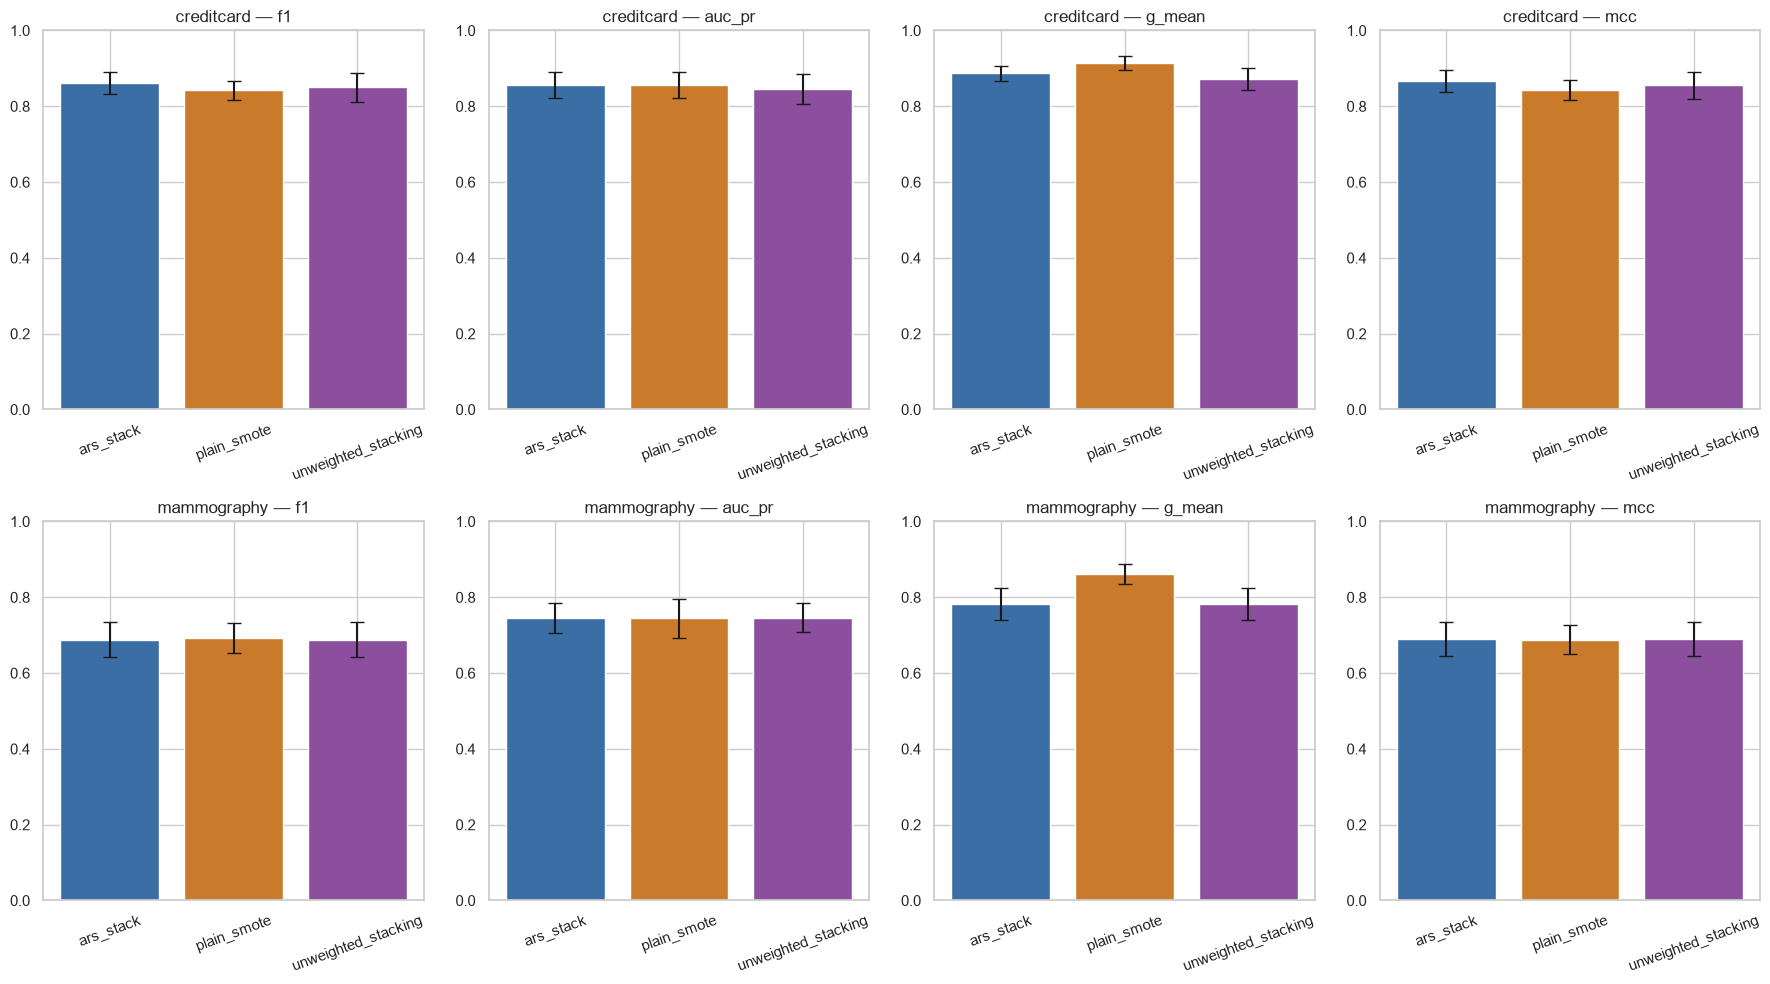

In [10]:
metrics_to_plot = ["f1", "auc_pr", "g_mean", "mcc"]

fig, axes = plt.subplots(len(DATASETS), len(metrics_to_plot), figsize=(18, 5 * len(DATASETS)))
if len(DATASETS) == 1:
    axes = axes.reshape(1, -1)

for row, dataset_name in enumerate(DATASETS):
    for col, metric in enumerate(metrics_to_plot):
        ax = axes[row][col]
        means, stds, labels = [], [], []
        for variant in VARIANTS:
            agg = aggregate_metrics(all_fold_results[(dataset_name, variant)])
            means.append(agg[metric]["mean"])
            stds.append(agg[metric]["std"])
            labels.append(variant)

        colors = ["#3B6EA5", "#C97A2B", "#8B4F9E"]
        ax.bar(labels, means, yerr=stds, capsize=5, color=colors)
        ax.set_title(f"{dataset_name} — {metric}")
        ax.set_ylim(0, 1)
        ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "ablation_comparison.png", dpi=150)
plt.show()


In [11]:
baseline_path = Path("../reports/baseline_results.csv")

if baseline_path.exists():
    baseline_df = pd.read_csv(baseline_path, index_col=0)
    print("Week 3 baseline reproduction (creditcard only):")
    display(baseline_df)
else:
    print("No Week 3 baseline_results.csv found — run notebooks/02_baseline_reproduction.ipynb first "
          "if you want it included in the final comparison.")


Week 3 baseline reproduction (creditcard only):


,f1,auc_pr,g_mean,mcc
model,,,,
RandomForest + SMOTE,0.8290,0.8678,0.9034,0.8288
XGBoost + SMOTE,0.7887,0.8729,0.9256,0.7909
Simple Stacking (RF+XGB) + SMOTE,0.8200,0.8706,0.9146,0.8198


In [12]:
rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE)

for fold_idx, (train_idx, test_idx) in enumerate(rskf.split(X, y)):
    if fold_idx >= 2: break
    X_train_outer, y_train_outer = X[train_idx], y[train_idx]
    X_tr, X_val, y_tr, y_val = train_test_split(X_train_outer, y_train_outer, test_size=0.15, stratify=y_train_outer, random_state=42)
    print(f"Fold {fold_idx}: val set size={len(y_val)}, val positives={y_val.sum()}")

Fold 0: val set size=1342, val positives=31
Fold 1: val set size=1342, val positives=31


In [13]:
print(f"Total time: {(time.time()-start)/60:.1f} min")

Total time: 562.9 min


## Takeaways (fill in after running with QUICK_TEST=False)

- [ ] Confirmed `QUICK_TEST=True` run completes without errors before running the real one
- [ ] Ran the full study with `QUICK_TEST=False` (5 folds x 3 repeats = 15 paired samples per comparison — required for Wilcoxon to be able to reach significance, see `significance_test.py`'s docstring)
- [ ] Noted whether adaptive resampling significantly beat plain SMOTE, per dataset
- [ ] Noted whether confidence weighting significantly beat unweighted stacking, per dataset
- [ ] Saved `reports/ablation_results/aggregated_summary.csv` and `ablation_comparison.png` for the final report
- [ ] If a comparison was NOT significant, that's a valid and reportable finding — don't discard it, discuss it honestly in the report's results section
